<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_WEEK_11_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

딥러닝 파이토치 교과서 ch7. p.393~417

## 05. LSTM

RNN은 결정적 단점이 있음. 앞서 언급했듯이 가중치가 업데이트되는 과정에서 기울기가 보다 작은 값이 계속 곱해지기 때문에 기울기가 사라지는 기울기 소멸 문제가 발생. 이를 해결하기 위해 LSTM 이나 GRU 같은 확장된 RNN 방식들을 사용하고 있음

### 1) LSTM 구조

**1. LSTM 순전파**

: LSTM은 기울기 소멸 문제를 해결하기 위해 망각 게이트 입력 게이트 출력 게이트라는 새로운 요소를 은닉층의 각 뉴런에 추가했음

**망각 게이트**

망각 게이트(forget gate): 과거 정보를 어느 정도 기억할지 결정함. 과거 정보와 현재 데이터를 입력받아 시그모이드를 취한 후 그 값을 과거 정보에 곱해 줌. 따라서 시그모이드의 출력이 0이면 과거 정보는 버리고, 1이면 과거 정보는 온전히 보존함


ht-1과 xt를 이용하여 이전 상태 정보를 현재 메모
리에 반영할지 결정하는 역할을 함
- 계산한 값이 1이면 바로 직전의 정보를 메모리에 유지
- 계산한 값이 0이면 초기화

망각 게이트에 대한 수식은 다음과 같음

<img src="https://drive.google.com/uc?export=view&id=1ju65nekfJP1h0Y8sPFtYDQUdpry85cPM" width="120">

그림으로는 다음과 같이 표현할 수 있음

<img src="https://drive.google.com/uc?export=view&id=1WkoG5jmDlXIuB4Dmzqx5wfuukNV75P09" width="300">

**입력 게이트**

입력 게이트(input gate): 현재 메모리에 새로운 정보를 반영할지 결정하는 역할

- 계산한 값이 1이면 입력 xt가 들어올 수 있도록 허용(open)
- 계산한 값이 0이면 차단

수식은 다음과 같음

<img src="https://drive.google.com/uc?export=view&id=1yf6SHkZqO5Cd7fpLUj-47bpsyEIFdTUt" width="120">

그림으로는 다음과 같이 표현할 수 있음

<img src="https://drive.google.com/uc?export=view&id=1OzIJPEKeC4BBF4N8sHGzjpdLcOpKCw4C" width="300">

**셀**

메모리 셀: 각 단계에 대한 은닉 노드(hidden node)
- 총합(sum)을 사용하여 셀 값을 반영하며, 이것으로 기울기 소멸 문제가 해결

셀을 업데이트하는 방법: 망각 게이트와 입력 게이트의 이전 단계 셀 정보를 계산하여 현재 단계의 셀 상태(cell state)를 업데이트

수식은 다음과 같음

<img src="https://drive.google.com/uc?export=view&id=1CQwO_gGlC2lGWLVrwISVa5UaUJMmHi60" width="120">

그림으로는 다음과 같이 표현할 수 있음

<img src="https://drive.google.com/uc?export=view&id=18y543GJy-XVELdo6L-ATrueVIRQdn7jP" width="300">

**출력 게이트**

출력 게이트(output gate): 과거 정보와 현재 데이터를 시용하여 뉴런의 출력을 결정. 이전 은닉 상태(hidden state)와 t번째 입력을 고려해서 다음 은닉 상태를 계산. 그리고 LSTM에서는 이 은닉 상태가 그 시점에서의 출력이 됨

출력 게이트는 갱신된 메모리의 출력 값을 제어하는 역할을 함
- 계산한 값이 1이면 의미 있는 결과로 최종 출력
- 계산한 값이 0이면 해당 연산 출력을 하지 않음

수식은 다음과 같음

<img src="https://drive.google.com/uc?export=view&id=17Jb3PSrP9coMiROL8phxl_R_yCHnmJZs" width="120">

그림으로는 다음과 같이 표현할 수 있음

<img src="https://drive.google.com/uc?export=view&id=1kPoAPG-M4PqDf0k0lCam9byOCpHE6gtV" width="300">

다음 그림은 망각 게이트, 입력 게이트, 출력 게이트를 모두 표현한 것

<img src="https://drive.google.com/uc?export=view&id=1VUvaJUoNkHQf0vcfSz-6xAUbmRi8alN5" width="300">

**2. LSTM 역전파**

LSTM은 셀을 통해서 역전파를 수행하기 때문에 '중단 없는 기울기(uninterrupted gradient flow)'라고도 함

즉, 다음 그림과 같이 최종 오자는 모든 노드에 전파되는데, 이때 셀을 통해서 중단 없이 전파됨

<img src="https://drive.google.com/uc?export=view&id=1XWN3pVG1tRU4qLIEfD0CYa3F-AIZsYkU" width="600">


다음은 역전파를 수행하기 위한 공식

<img src="https://drive.google.com/uc?export=view&id=1hk4sKckvmcXpBYAVKPEEcNjwwoVwwcqu" width="130">

이때 주의해야 할 것은 셀 단위로 오차가 전파된다고 해서 입력 방향으로 오차가 전파되지 않는
것은 아님.

다음 그림과 같이 셀 내부적으로는 오차가 입력(xt)으로 전파된다는 것도 잊지 말아야 함

<img src="https://drive.google.com/uc?export=view&id=1i81oEKvoshF9KvSTuLJcn9QrCXdLskJG" width="250">


### 2) LSTM 셀 구현





In [1]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.autograd import Variable
from torch.nn import Parameter # 파라미터 목록을 갖고 있는 라이브러리(패키지)
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math # 수학과 관련되어 다양한 함수들과 상수들이 정의되어 있는 라이브러리

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False # GPU 사용에 필요(GPU는 8장에서 자세히 살펴볼
                                                    # 예정이지만 미리 눈으로 익혀 두세요)
Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor # GPU 사용에 필요

torch.manual_seed(125)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(125)

In [2]:
import torchvision.transforms as transforms

mnist_transform = transforms .Compose([
    transforms.ToTensor(),
    transforms. Normalize((0.5, ), (1.0,)) # 평균을 0.5, 표준편차를 1.0으로 데이터 정규화
])                                         # (데이터 분포를 조정)

In [3]:
from torchvision.datasets import MNIST

download_root = '../chap07/MNIST_DATASET' # MNIST를 내려받을 경로

train_dataset = MNIST(download_root, transform=mnist_transform, train=True , download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False, download=True)

In [4]:
batch_size = 64
train_loader = DataLoader(dataset=train_dataset,
                          batch_size=batch_size,
                          shuffle=True)
valid_loader = DataLoader(dataset=test_dataset,
                          batch_size=batch_size,
                          shuffle=True)
test_loader = DataLoader(dataset=test_dataset,
                         batch_size=batch_size,
                         shuffle=True)

In [5]:
batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

In [6]:
class LSTMCell(nn.Module):
  def __init__(self, input_size, hidden_size, bias=True):
    super(LSTMCell, self).__init__()
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.bias = bias
    self.x2h = nn.Linear(input_size, 4 * hidden_size, bias=bias)
    self.h2h = nn.Linear(hidden_size, 4 * hidden_size, bias=bias)
    self.reset_parameters()

  def reset_parameters(self):
    std = 1.0 / math.sqrt(self.hidden_size)
    for w in self.parameters():
      w.data.uniform_(-std, std)

  def forward(self, x, hidden):
    hx, cx = hidden
    x = x.view(-1, x.size(1))

    gates = self.x2h(x) + self.h2h(hx)
    gates = gates.squeeze()
    ingate, forgetgate, cellgate, outgate = gates.chunk(4, 1)

    ingate = F.sigmoid(ingate)
    forgetgate = F.sigmoid(forgetgate)
    cellgate = F.tanh(cellgate)
    outgate = F.sigmoid(outgate)

    cy = (forgetgate * cx) + (ingate * cellgate)
    hy = outgate * F.tanh(cy)
    return (hy, cy)

<img src="https://drive.google.com/uc?export=view&id=1bVowoBljDZpcjh5wScwATcrNMIL671Jo" width="450">

그림 7-23과 같이 LSTM에서 중요한 것은 게이트임

게이트는 망각 입력, 셀, 출력으로 구성되며 이 모든 게이트는

gates = self.x2h(x) + self.h2h(hx)
처럼 구할 수 있음

In [7]:
class LSTMModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
    super(LSTMModel, self).__init__()
    self.hidden_dim = hidden_dim # 은닉층의 뉴런/유닛 개수

    self.layer_dim = layer_dim
    self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
    self.fc = nn.Linear(hidden_dim, output_dim)

  def forward(self, x):
    if torch.cuda.is_available(): # GPU 사용 유뮤 확인
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
      # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 형태를 갖는 은닉 상태를 0으로 초기화
    else:
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    if torch.cuda.is_available():
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
      # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 형태를 갖는 셀 상태를 0으로 초기화
    else:
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    outs = []
    cn = c0[0,:,:] # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 크기를 갖는 셀 상태에 대한 텐서
    hn = h0[0,:,:] # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 크기를 갖는 은닉 상태에 대한 텐서

    for seq in range(x.size(1)): # LSTM 셀 계층을 반복하여 쌓아 올립니다.
      hn, cn = self.lstm(x[:,seq,:], (hn, cn)) # 은닉 상태(hn)와 셀 상태를 LSTMCell에 적용한 결과를
      outs.append(hn)                          # 또다시 hn, cn에 저장

    out = outs[-1].squeeze()
    out = self.fc(out)
    return out

In [8]:
input_dim = 28
hidden_dim = 100
layer_dim = 1
output_dim = 10

model = LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available(): # GPU 사용 유무 확인
  model.cuda()
criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [9]:
seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader): # 훈련 데이터셋을 이용한 모델 학습
    if torch.cuda.is_available(): # GPU 사용 유뮤 확인
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = labels.cuda()
    else:  # GPU를 사용하지 않기 때문에 else 구문이 실행
      images = Variable(images.view(-1, seq_dim, input_dim))
      labels = Variable(labels)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels) # 손실 함수를 이용하여 오차 계산

    if torch.cuda.is_available():
      loss.cuda()

    loss.backward()
    optimizer.step()  # 파라미터 업데이트
    loss_list.append(loss.item())
    iter += 1

    if iter % 500 == 0:  # 정확도(accuracy) 계산
      correct = 0
      total = 0
      for images, labels in valid_loader: # 검증 데이터셋을 이용한 모델 성능 검증

        if torch.cuda.is_available():
          images = Variable(images.view(-1, seq_dim, input_dim).cuda())
        else:
          images = Variable(images.view(-1, seq_dim, input_dim))
          outputs = model(images)
          _, predicted = torch.max(outputs.data,1) # 모델을 통과한 결과의 최댓값으로부터 예측 결과 가져오기

          total += labels.size(0) # 총 레이블 수
          if torch.cuda.is_available():
            correct += (predicted.cpu() == labels.cpu()).sum()
          else:
            correct += (predicted == labels).sum()

      accuracy = 100 * correct / total
      print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(), accuracy))

Iteration: 500. Loss: 2.2470498085021973. Accuracy: 24.979999542236328
Iteration: 1000. Loss: 0.882879912853241. Accuracy: 74.70999908447266
Iteration: 1500. Loss: 0.3326823115348816. Accuracy: 88.05000305175781
Iteration: 2000. Loss: 0.22052308917045593. Accuracy: 92.55999755859375
Iteration: 2500. Loss: 0.22818301618099213. Accuracy: 95.13999938964844
Iteration: 3000. Loss: 0.11971761286258698. Accuracy: 95.81999969482422
Iteration: 3500. Loss: 0.0373678021132946. Accuracy: 96.91999816894531
Iteration: 4000. Loss: 0.15393488109111786. Accuracy: 95.87000274658203
Iteration: 4500. Loss: 0.04160100594162941. Accuracy: 96.95999908447266
Iteration: 5000. Loss: 0.04042982682585716. Accuracy: 97.4800033569336
Iteration: 5500. Loss: 0.04942428693175316. Accuracy: 97.37000274658203
Iteration: 6000. Loss: 0.05389028787612915. Accuracy: 97.2699966430664
Iteration: 6500. Loss: 0.0172437634319067. Accuracy: 97.68000030517578
Iteration: 7000. Loss: 0.10595524311065674. Accuracy: 97.86000061035156


In [10]:
def evaluate(model, val_iter):
  corrects, total, total_loss = 0, 0, 0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available():
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = labels.cuda()
    else:
      images = Variable(images.view(-1, seq_dim, input_dim)).to(device)

    logit = model(images).to(device)
    loss = F.cross_entropy(logit, labels, reduction="sum")
    _, predicted = torch.max(logit, 1) # logit.data 텐서에서 최댓값의 인덱스를 반환
    total += labels.size(0)
    total_loss += loss.item()
    corrects += (predicted == labels).sum()

  avg_loss = total_loss / len(val_iter.dataset)
  avg_accuracy = corrects / total
  return avg_loss, avg_accuracy

In [11]:
test_loss, test_acc = evaluate(model, test_loader)
print('Test Loss: {}, Test Accuracy: {}'.format(test_loss, test_acc))

Test Loss: 0.06498212732803077, Test Accuracy: 0.9811999797821045


### 3) LSTM 계층 구현


In [12]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [13]:
!git clone https://github.com/gilbutITbook/080289.git ### 추가 ###

fatal: destination path '080289' already exists and is not an empty directory.


In [14]:
data = pd.read_csv('/content/080289/chap07/data/SBUX.csv')
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


In [15]:
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True) # 'Date' 칼럼을 인덱스로 사용

In [16]:
data['Volume'] = data['Volume'].astype(float) # 데이터 형식을 변경할 때는 astupe()을 사용

In [17]:
X = data.iloc[:, :-1] # 마지막 칼럼을 제외한 모든 칼럼을 x로 사용
y = data.iloc[:, 5:6] # 마지막 'Volume'을 레이블로 사용
print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
                Volume
Date                  
2019-12

In [18]:
ms = MinMaxScaler()    # 데이터의 모든 값이 0~1 사이에 존재하도록 분산 조정
ss = StandardScaler()  # 데이터가 평균 0, 분산 1이 되도록 분산 조정

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]  # 훈련 데이터셋
X_test = X_ss[200:, :]   # 테스트 데이터셋

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Testing Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


In [19]:
X_train_tensors = Variable(torch.Tensor(X_train))
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                    1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                   1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


In [20]:
class LSTM(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(LSTM, self).__init__()
    self.num_classes = num_classes  # 클래스 개수
    self.num_layer = num_layers # LSTM 계층의 개수
    self.input_size = input_size # 입력 크기로 훈련 데이터셋의 칼럼 개수를 의미
    self.hidden_size = hidden_size # 은닉층의 뉴런 개수
    self.seq_length = seq_length # 시퀀스 길이

    self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                        num_layers=num_layers, batch_first = True)  # LSTM 계층
    self.fc_1 = nn.Linear(hidden_size, 128)  # 완전연결층
    self.fc = nn.Linear(128, num_classes)  # 출력층
    self.relu = nn.ReLU()

  def forward(self,x):
    h_0 = Variable(torch.zeros(self.num_layer, x.size(0), self.hidden_size))
    c_0 = Variable(torch.zeros(self.num_layer, x.size(0), self.hidden_size))
    output, (hn, cn) = self.lstm(x, (h_0, c_0))
    hn = hn.view(-1, self.hidden_size)
    out = self.relu(hn)
    out = self.fc_1(out)
    out = self.relu(out)
    out = self.fc(out)
    return out

In [21]:
num_epochs = 1000 # 1000번의 에포크
learning_rate = 0.0001 # 학습률을 0.0001로 지정

input_size = 5 # 입력 데이터세스이 칼럼(feature) 개수
hidden_size = 2 # 은닉층의 뉴런/유닛 개수
num_layers = 1 # LSTM 계층의 개수

num_classes = 1
model = LSTM(num_classes, input_size, hidden_size, num_layers,
             X_train_tensors_f.shape[1]) # 앞에서 정의한 값들을 이용하여 LSTM 모델 학습

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [22]:
for epoch in range (num_epochs): # 1000번 반복
    outputs = model. forward(X_train_tensors_f) # 전방항(torward) 학습
    optimizer.zero_grad()
    loss = criterion (outputs, y_train_tensors) # 손실 함수를 이용한 오차 계산(모델 학습 결과(output)와
                                                # 레이블(y_train_tensors)의 차이 계산)
    loss.backward() # 기울기 계산
    optimizer. step() # 오차 업데이트
    if epoch % 100 == 0: # 1000을 100으로 나누어 나머지가 0이면 출력
      print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.14627
Epoch: 100, loss: 0.05548
Epoch: 200, loss: 0.03868
Epoch: 300, loss: 0.03623
Epoch: 400, loss: 0.03474
Epoch: 500, loss: 0.03324
Epoch: 600, loss: 0.03231
Epoch: 700, loss: 0.03172
Epoch: 800, loss: 0.03115
Epoch: 900, loss: 0.03053


In [23]:
df_x_ss = ss.transform(data.iloc[ :, : -1]) # 데이터 정규화(분포 조정)
df_y_ms = ms.transform(data.iloc[ :, -1:])  # 데이터 정규화

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

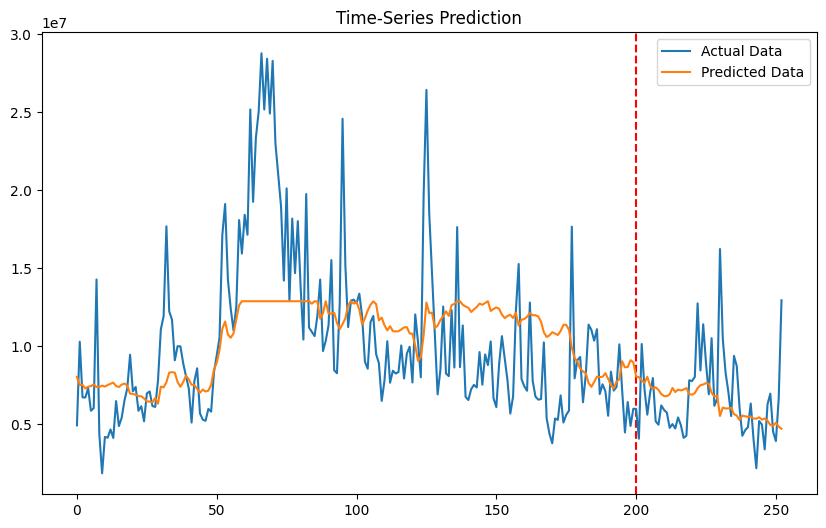

In [24]:
train_predict = model(df_x_ss) # 훈련 데이터셋을 모댈에 적용하여 모댈 학습
predicted = train_predict.data.numpy() # 모델 학습 결과를 넘파이로 변경
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)# 모델 학습을 위해 전처리(정규화)했던 것을 해제
                                           # (그래프의 본래 값을 출력하기 위한 목적)
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10,6)) # 그래프로 표시(plotting)
plt.axvline(x=200, c= 'r', linestyle= '--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()